Dimensiones del recorte: 180 x 140


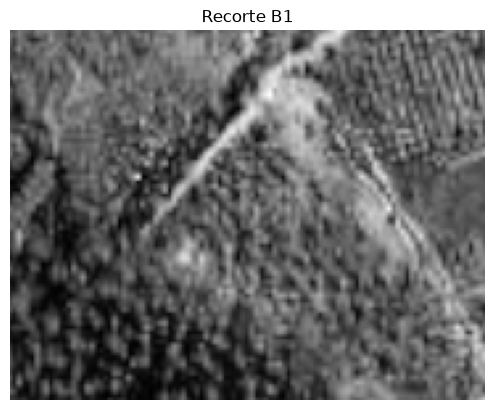

Ruta de acceso   : C:\Users\VICTUS\calca_satelital.png
Clase del objeto : <class 'numpy.ndarray'>
Dimensiones      : (728, 1077, 3)  [Y, X, C]
Ancho x Alto     : 1077 x 728 px
Canales          : 3
Rango de valores : 0.000 - 1.000
Dim matriz R: (728, 1077) | media R: 0.4303
Dim matriz B: (728, 1077) | media B: 0.4679
Luminancia media Y (BT.601) = 0.4642
Control rgb2gray() (Rec.709) = 0.4691
ROI central: 150 x 150 px


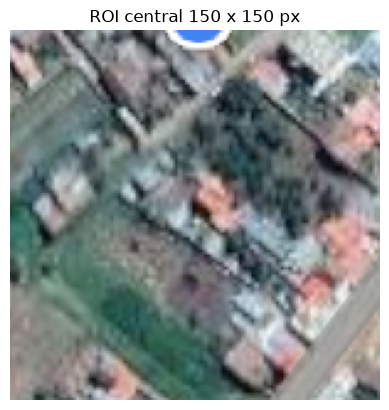


===== PARTE D =====
Umbral optimo (Otsu) = 0.4553
Cobertura segmentada = 53.5 %
Umbral skimage Otsu  = 0.4553
Coincidencia con threshold_otsu(): 100.0 %


C:\Users\VICTUS\AppData\Local\Temp\ipykernel_4260\1865423153.py:133: RuntimeWarning: invalid value encountered in divide
  sb = (mu[-1] * w0 - mu) ** 2 / (w0 * (1 - w0))   # varianza entre clases


FileNotFoundError: [Errno 2] No such file or directory: '/content\\resultado_D.png'

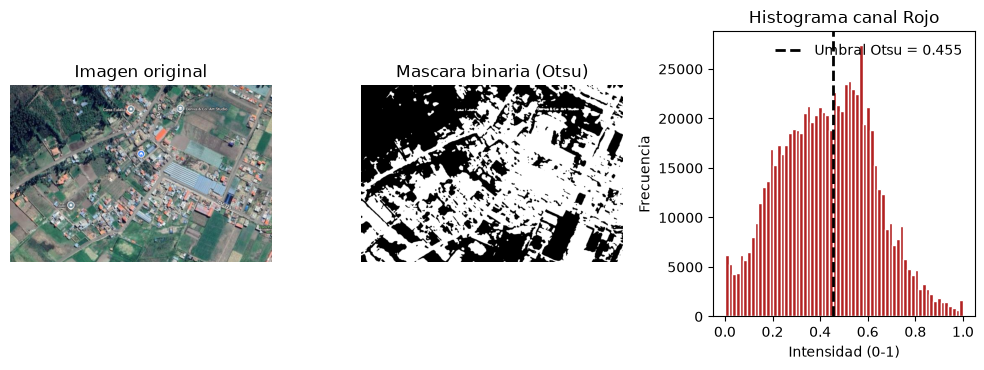

In [2]:
# ============================================================
# B1 en Python
# Equivalente al original en R (imager → scikit-image)
#   img  = imread('calca_satelital.png')
#   gray = rgb2gray(img)
#   crop = gray[10:150, 20:200]
# ============================================================
import os
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, color
from skimage.util import img_as_float

ruta = "calca_satelital.png"

# img = imread('calca_satelital.png')
img = img_as_float(io.imread(ruta))          # escala a [0,1] como imager::load.image
if img.ndim == 3 and img.shape[2] == 4:      # quita canal alfa si existe
    img = img[:, :, :3]

# gray = rgb2gray(img)  (BT.601, igual que imager::grayscale)
if img.ndim == 3:
    gray = 0.299 * img[:, :, 0] + 0.587 * img[:, :, 1] + 0.114 * img[:, :, 2]
else:
    gray = img

# crop = gray[10:150, 20:200]
# Python: filas 10..149, columnas 20..199 (fin excluido)
crop = gray[10:150, 20:200]

alto_c, ancho_c = crop.shape[:2]
print(f"Dimensiones del recorte: {ancho_c} x {alto_c}")
# 180 x 140   (ancho x alto)

plt.imshow(crop, cmap="gray")
plt.title("Recorte B1")
plt.axis("off")
plt.show()


# ============================================================
# PARTE C - Canales, luminancia y ROI central 150 x 150
# ============================================================
ruta = 'calca_satelital.png'
carpeta = "/content"

img = img_as_float(io.imread(ruta))
if img.ndim == 3 and img.shape[2] == 4:
    img = img[:, :, :3]

alto, ancho = img.shape[:2]
canales = img.shape[2] if img.ndim == 3 else 1

# ---- 1. Carga y metadatos ----
print(f"Ruta de acceso   : {os.path.abspath(ruta)}")
print(f"Clase del objeto : {type(img)}")
print(f"Dimensiones      : {img.shape}  [Y, X, C]")
print(f"Ancho x Alto     : {ancho} x {alto} px")
print(f"Canales          : {canales}")
print(f"Rango de valores : {img.min():.3f} - {img.max():.3f}")

# ---- 2. Matrices de los canales R y B ----
if img.ndim == 3:
    canal_R = img[:, :, 0]
    canal_B = img[:, :, 2]
else:
    canal_R = canal_B = img

print(f"Dim matriz R: {canal_R.shape} | media R: {canal_R.mean():.4f}")
print(f"Dim matriz B: {canal_B.shape} | media B: {canal_B.mean():.4f}")

# ---- 3. Luminancia BT.601 y su promedio ----
if img.ndim == 3:
    Y = 0.299 * img[:, :, 0] + 0.587 * img[:, :, 1] + 0.114 * img[:, :, 2]
else:
    Y = img

# Control con skimage (Rec.709: 0.2125, 0.7154, 0.0721) — puede diferir levemente
gray_control = color.rgb2gray(img) if img.ndim == 3 else img

print(f"Luminancia media Y (BT.601) = {Y.mean():.4f}")
print(f"Control rgb2gray() (Rec.709) = {gray_control.mean():.4f}")

# ---- 4. ROI central de 150 x 150 px ----
if ancho < 150 or alto < 150:
    raise ValueError(f"La imagen mide {ancho} x {alto} px; se necesita al menos 150 x 150 px.")

x0 = (ancho - 150) // 2
y0 = (alto  - 150) // 2

roi = img[y0:y0 + 150, x0:x0 + 150]
assert roi.shape[0] == 150 and roi.shape[1] == 150

print(f"ROI central: {roi.shape[1]} x {roi.shape[0]} px")

plt.imshow(roi)
plt.title("ROI central 150 x 150 px")
plt.axis("off")
plt.show()


# ============================================================
# PARTE D - Suavizado, Otsu, histograma del canal Rojo (300 DPI)
# ============================================================
from scipy.ndimage import gaussian_filter
from skimage import filters

ruta = "calca_satelital.png"
carpeta = "/content"

img = img_as_float(io.imread(ruta))
if img.ndim == 3 and img.shape[2] == 4:
    img = img[:, :, :3]

print("\n===== PARTE D =====")

# ---- 1. Escala de grises + suavizado Gaussiano sigma = 2 ----
if img.ndim == 3:
    gris = 0.299 * img[:, :, 0] + 0.587 * img[:, :, 1] + 0.114 * img[:, :, 2]
else:
    gris = img

blur = gaussian_filter(gris, sigma=2)

# ---- 2. Umbral automatico de Otsu ----
def otsu(x, nbins=256):
    x = np.asarray(x).ravel()
    h, edges = np.histogram(x, bins=nbins, range=(x.min(), x.max()))
    p = h / h.sum()
    mids = (edges[:-1] + edges[1:]) / 2
    w0 = np.cumsum(p)
    mu = np.cumsum(p * mids)
    sb = (mu[-1] * w0 - mu) ** 2 / (w0 * (1 - w0))   # varianza entre clases
    return mids[np.nanargmax(sb)]

t_opt = otsu(blur)
mask  = blur > t_opt                                # True = zona clara

print(f"Umbral optimo (Otsu) = {t_opt:.4f}")
print(f"Cobertura segmentada = {100 * mask.mean():.1f} %")

# Control con skimage
t_sk = filters.threshold_otsu(blur)
mask_auto = blur > t_sk
print(f"Umbral skimage Otsu  = {t_sk:.4f}")
print(f"Coincidencia con threshold_otsu(): {100 * (mask == mask_auto).mean():.1f} %")

# ---- 3 y 4. Figura compuesta y guardado a 300 DPI ----
rojo = (img[:, :, 0] if img.ndim == 3 else img).ravel()

def dibujar_figura():
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.8))

    axes[0].imshow(img)
    axes[0].set_title("Imagen original")
    axes[0].axis("off")

    axes[1].imshow(mask, cmap="gray")
    axes[1].set_title("Mascara binaria (Otsu)")
    axes[1].axis("off")

    axes[2].hist(rojo, bins=64, color="firebrick", edgecolor="white")
    axes[2].set_title("Histograma canal Rojo")
    axes[2].set_xlabel("Intensidad (0-1)")
    axes[2].set_ylabel("Frecuencia")
    axes[2].axvline(t_opt, color="black", lw=2, ls="--",
                    label=f"Umbral Otsu = {t_opt:.3f}")
    axes[2].legend(loc="upper right", frameon=False)

    fig.tight_layout()
    return fig

fig = dibujar_figura()

# (b) Guardar a 300 DPI (10 x 3.8 in = 3000 x 1140 px)
salida_fig = os.path.join(carpeta, "resultado_D.png")
fig.savefig(salida_fig, dpi=300)
print(f"Figura guardada en: {salida_fig}  (300 DPI)")

# (a) Mostrar en pantalla
plt.show()
plt.close(fig)